# EV Battery State-of-Charge and Health Estimation with a Linear Dynamical System (Kalman Filter)
**Dataset:** Panasonic 18650PF lithium-ion cell (25 °C tests)  
**Goal:** estimate the hidden State of Charge (SOC) and health (capacity, resistance) from noisy current, voltage and temperature measurements.

In [ ]:
# Locate the dataset (upload the zip to Colab first, or mount Google Drive)

import os, zipfile

ZIP_PATH = "/content/wykht8y7tg-1.zip"      # change if your zip has another name or location
DATA_DIR = "/content/battery_data"

if os.path.exists(ZIP_PATH) and not os.path.isdir(DATA_DIR):
    assert zipfile.is_zipfile(ZIP_PATH), "Zip is corrupt or incomplete - upload it again"
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

if not os.path.isdir(DATA_DIR):             # fallback: data already extracted in the working folder
    DATA_DIR = "."

print("Data directory:", DATA_DIR)

Data directory: .


In [ ]:
# Import libraries

import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io as sio

from IPython.display import display
from scipy.interpolate import PchipInterpolator
from scipy.optimize import least_squares

warnings.filterwarnings("ignore")
np.random.seed(42)

In [ ]:
# Helper functions to locate and load measurement files

def find(pattern):
    matches = glob.glob(os.path.join(DATA_DIR, "**", pattern), recursive=True)
    if not matches:
        raise FileNotFoundError(f"No file matching {pattern} under {DATA_DIR}")
    return matches[0]

def load_mat(path):
    m = sio.loadmat(path)["meas"][0, 0]
    get = lambda key: m[key].ravel().astype(float)
    return dict(t=get("Time"), V=get("Voltage"), I=get("Current"), T=get("Battery_Temp_degC"))

def cumulative_charge(I, t):
    # cumulative charge in Ah using the trapezoidal rule
    return np.concatenate([[0], np.cumsum(0.5 * (I[1:] + I[:-1]) * np.diff(t))]) / 3600

In [ ]:
# Load the 1C discharge cycles

def discharge_part(d):
    on = np.where(d["I"] < -1)[0]
    s, e = on[0], on[-1] + 1
    return {k: v[s:e] for k, v in d.items()}

cycles = {}
for name, pattern in [("Dis1C_1", "*3349_Dis1C_1.mat"), ("Dis1C_2", "*3349_Dis1C_2.mat")]:
    d = discharge_part(load_mat(find(pattern)))
    d["t"] = d["t"] - d["t"][0]
    d["Q"] = -cumulative_charge(d["I"], d["t"])[-1]                      # delivered capacity [Ah]
    d["soc_ref"] = 1 - (-cumulative_charge(d["I"], d["t"])) / d["Q"]     # reference SOC: 100% -> 0%
    cycles[name] = d

summary = pd.DataFrame({
    name: {
        "Samples": len(d["t"]),
        "Duration (min)": d["t"][-1] / 60,
        "Sampling interval (s)": np.median(np.diff(d["t"])),
        "Discharge current (A)": d["I"].mean(),
        "Voltage range (V)": f"{d['V'].min():.2f} - {d['V'].max():.2f}",
        "Temperature range (C)": f"{d['T'].min():.1f} - {d['T'].max():.1f}",
        "Delivered capacity (Ah)": d["Q"],
    } for name, d in cycles.items()
}).T
display(summary)

,Samples,Duration (min),Sampling interval (s),Discharge current (A),Voltage range (V),Temperature range (C),Delivered capacity (Ah)
Dis1C_1,349,57.90615,9.999996,-2.899418,2.50 - 4.04,25.0 - 32.7,2.798236
Dis1C_2,343,56.942633,9.999996,-2.899387,2.50 - 4.05,25.6 - 32.3,2.751646


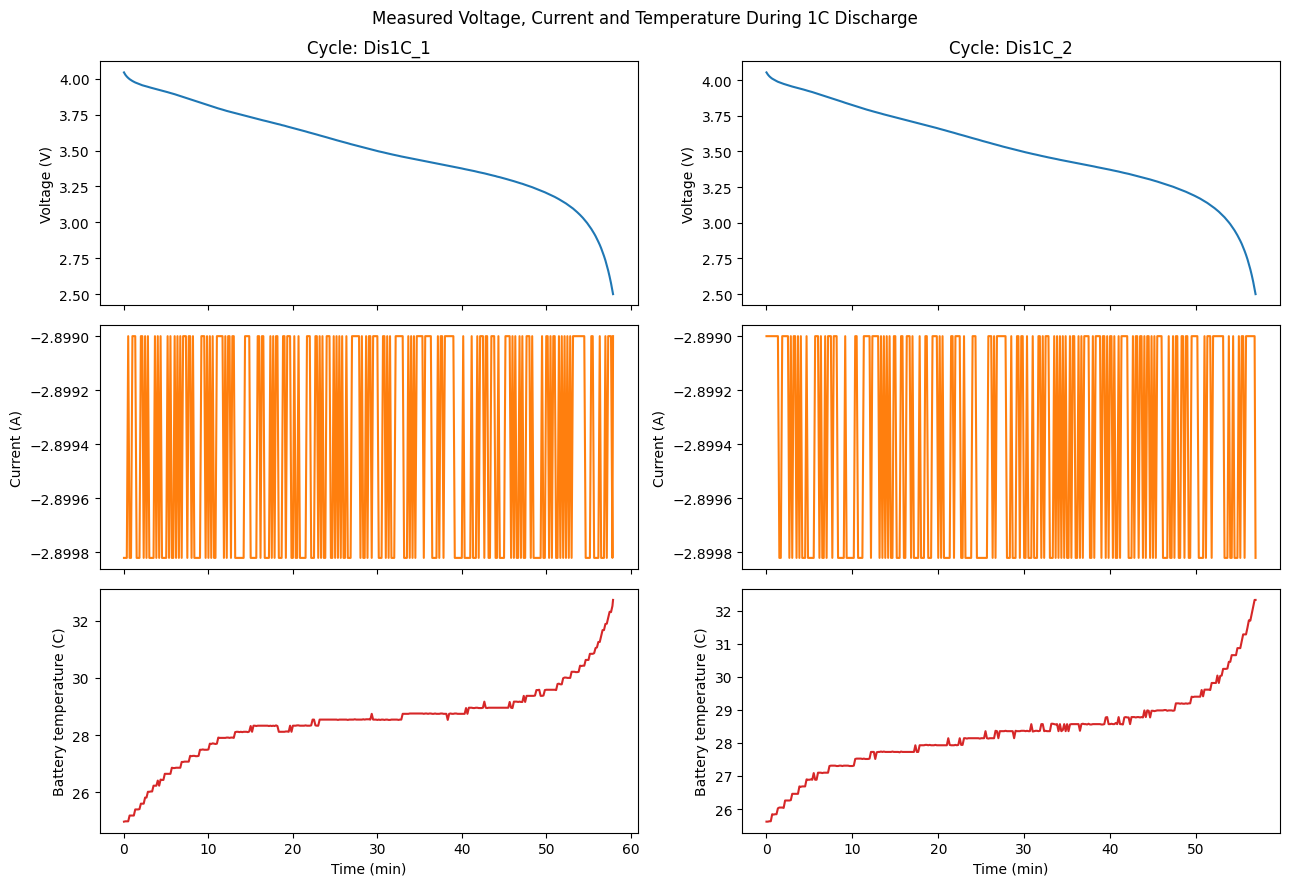

In [ ]:
# Display the raw measurements

fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex="col")

for col, (name, d) in enumerate(cycles.items()):
    tm = d["t"] / 60
    axes[0, col].plot(tm, d["V"])
    axes[0, col].set_ylabel("Voltage (V)")
    axes[0, col].set_title(f"Cycle: {name}")
    axes[1, col].plot(tm, d["I"], color="tab:orange")
    axes[1, col].set_ylabel("Current (A)")
    axes[2, col].plot(tm, d["T"], color="tab:red")
    axes[2, col].set_ylabel("Battery temperature (C)")
    axes[2, col].set_xlabel("Time (min)")

plt.suptitle("Measured Voltage, Current and Temperature During 1C Discharge")
plt.tight_layout()
plt.show()

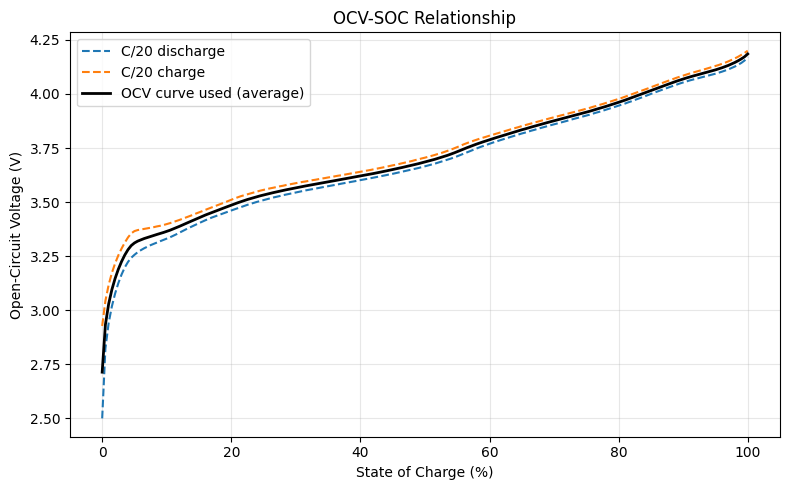

C/20 discharge capacity: 2.995 Ah


In [ ]:
# Build the open-circuit voltage (OCV) vs. SOC curve from the C/20 test

c20 = load_mat(find("*C20 OCV Test*25dC.mat"))
t, I, V = c20["t"], c20["I"], c20["V"]

idx_dis = np.where(I < -0.05)[0]
idx_chg = np.where(I > 0.05)[0]
dis = slice(idx_dis[0], idx_dis[-1] + 1)
chg = slice(idx_chg[0], idx_chg[-1] + 1)

q_dis = -cumulative_charge(I[dis], t[dis]);  soc_dis = 1 - q_dis / q_dis[-1]
q_chg = cumulative_charge(I[chg], t[chg]);   soc_chg = q_chg / q_chg[-1]

grid = np.linspace(0, 1, 201)
V_dis = np.interp(grid, soc_dis[::-1], V[dis][::-1])
V_chg = np.interp(grid, soc_chg, V[chg])

ocv_grid = np.maximum.accumulate(0.5 * (V_dis + V_chg))
ocv_grid = ocv_grid + np.arange(len(grid)) * 1e-9        # strictly increasing for interpolation
OCV = PchipInterpolator(grid, ocv_grid)
dOCV = OCV.derivative()

plt.figure(figsize=(8, 5))
plt.plot(100 * grid, V_dis, "--", label="C/20 discharge")
plt.plot(100 * grid, V_chg, "--", label="C/20 charge")
plt.plot(100 * grid, ocv_grid, "k", linewidth=2, label="OCV curve used (average)")
plt.xlabel("State of Charge (%)")
plt.ylabel("Open-Circuit Voltage (V)")
plt.title("OCV-SOC Relationship")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"C/20 discharge capacity: {q_dis[-1]:.3f} Ah")

In [ ]:
# Identify the equivalent-circuit parameters (R0, R1, tau and temperature dependence)
# R(T) = R_ref * exp(Ea / T_k - Ea / T_ref), T_ref = 25 C

TREF = 298.15

def arrhenius(Ea, T):
    return np.exp(Ea * (1 / (T + 273.15) - 1 / TREF))

def simulate_voltage(p, d):
    R0, R1, tau, Ea0, Ea1 = p
    V1 = 0.0
    out = np.zeros(len(d["t"]))
    dt = np.diff(d["t"], prepend=d["t"][0] + 10)
    for k in range(len(out)):
        a = np.exp(-dt[k] / tau)
        V1 = a * V1 + R1 * arrhenius(Ea1, d["T"][k]) * (1 - a) * d["I"][k]
        out[k] = OCV(np.clip(d["soc_ref"][k], 0, 1)) + V1 + R0 * arrhenius(Ea0, d["T"][k]) * d["I"][k]
    return out

def residuals(p):
    d = cycles["Dis1C_1"]
    return (simulate_voltage(p, d) - d["V"])[3:-5]

fit = least_squares(
    residuals,
    x0=[0.04, 0.02, 60, 1000, 1000],
    bounds=([0.005, 0.001, 5, 0, 0], [0.2, 0.2, 500, 5000, 5000])
)
R0_REF, R1_REF, TAU, EA0, EA1 = fit.x
model_rmse = np.sqrt(np.mean(fit.fun ** 2))

params_df = pd.DataFrame({
    "Parameter": ["R0 (mOhm)", "R1 (mOhm)", "tau (s)", "Ea0 (K)", "Ea1 (K)", "Voltage RMSE (mV)"],
    "Value": [R0_REF * 1e3, R1_REF * 1e3, TAU, EA0, EA1, model_rmse * 1e3]
})
display(params_df.round(3))

,Parameter,Value
0,R0 (mOhm),48.120
1,R1 (mOhm),22.403
2,tau (s),500.000
3,Ea0 (K),0.000
4,Ea1 (K),0.000
5,Voltage RMSE (mV),37.493


In [ ]:
# Kalman filter (linear dynamical system) for SOC, capacity and resistance
# State x = [SOC, V1 (RC voltage), R0 (at 25 C), theta = 1/Q]
#   x[k+1] = F[k] x[k] + w[k]
#   y[k]   = OCV(SOC[k]) + V1[k] + f(T[k]) * R0[k] * I[k] + v[k]     (OCV linearised -> H[k])

def corrupt(d, sig_V, sig_I, sig_T, rng):
    n = len(d["t"])
    return (d["V"] + rng.normal(0, sig_V, n),
            d["I"] + rng.normal(0, sig_I, n),
            d["T"] + rng.normal(0, sig_T, n))

def kalman_filter(d, V_m, I_m, T_m, soc0, Q0, sig_V, sig_I, adapt=True):
    n = len(d["t"])
    dt = np.diff(d["t"], prepend=d["t"][0] + 10)

    x = np.array([soc0, 0.0, R0_REF, 1.0 / Q0])
    P = np.diag([0.1 ** 2, 0.01 ** 2, 0.01 ** 2, (0.3 / Q0) ** 2])
    Qn = np.diag([
        (sig_I * dt.mean() / 3600 / Q0) ** 2 + 1e-9,
        1e-6,
        (1e-6 if adapt else 0) ** 2,
        (3e-6 if adapt else 0) ** 2,
    ])
    Rn = sig_V ** 2

    soc, cap, res, vpred, sd = (np.zeros(n) for _ in range(5))

    for k in range(n):
        # Predict
        a = np.exp(-dt[k] / TAU)
        u = dt[k] * I_m[k] / 3600.0
        F = np.array([[1, 0, 0, u], [0, a, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1.0]])
        x = np.array([
            x[0] + u * x[3],
            a * x[1] + R1_REF * arrhenius(EA1, T_m[k]) * (1 - a) * I_m[k],
            x[2],
            x[3],
        ])
        P = F @ P @ F.T + Qn

        # Update
        s = np.clip(x[0], 0, 1)
        fT = arrhenius(EA0, T_m[k])
        y_hat = OCV(s) + x[1] + fT * x[2] * I_m[k]
        H = np.array([float(dOCV(s)), 1.0, fT * I_m[k], 0.0])
        S = H @ P @ H + Rn
        K = P @ H / S
        x = x + K * (V_m[k] - y_hat)
        P = (np.eye(4) - np.outer(K, H)) @ P

        x[0] = np.clip(x[0], 0, 1)
        x[2] = max(x[2], 1e-3)
        x[3] = np.clip(x[3], 1 / 4.0, 1 / 1.5)

        soc[k], cap[k], res[k] = x[0], 1 / x[3], x[2]
        vpred[k], sd[k] = y_hat, np.sqrt(P[0, 0])

    return dict(soc=soc, Q=cap, R0=res, V=vpred, sd=sd)

def coulomb_counting(d, I_m, soc0, Q0):
    return soc0 + cumulative_charge(I_m, d["t"]) / Q0

def ocv_lookup(V_m, I_m):
    # Naive voltage-only SOC: invert the OCV curve after removing the ohmic drop
    v_corr = V_m - R0_REF * I_m
    return np.interp(v_corr, ocv_grid, grid)

def rmse(a, b):
    return 100 * np.sqrt(np.mean((a - b) ** 2))

In [ ]:
# Run the estimators on noisy data with a wrong initial SOC and wrong capacity guess

SIG_V, SIG_I, SIG_T = 0.010, 0.05, 0.5      # sensor noise: 10 mV, 0.05 A, 0.5 C
SOC0_GUESS, Q_NOMINAL = 0.70, 2.9

rng = np.random.default_rng(42)
runs = {}

for name, d in cycles.items():
    V_m, I_m, T_m = corrupt(d, SIG_V, SIG_I, SIG_T, rng)
    runs[name] = dict(
        V_m=V_m, I_m=I_m,
        kf=kalman_filter(d, V_m, I_m, T_m, SOC0_GUESS, Q_NOMINAL, SIG_V, SIG_I),
        cc=coulomb_counting(d, I_m, SOC0_GUESS, Q_NOMINAL),
        ocv=ocv_lookup(V_m, I_m),
    )

rows = []
for name, d in cycles.items():
    r = runs[name]
    rows.append({
        "Cycle": name,
        "Kalman Filter SOC RMSE (%)": rmse(r["kf"]["soc"], d["soc_ref"]),
        "Coulomb Counting SOC RMSE (%)": rmse(r["cc"], d["soc_ref"]),
        "Voltage-Only SOC RMSE (%)": rmse(r["ocv"], d["soc_ref"]),
        "KF Max |Error| After 10 min (%)": 100 * np.max(np.abs(r["kf"]["soc"][60:] - d["soc_ref"][60:])),
    })

soc_results_df = pd.DataFrame(rows)
display(soc_results_df.round(3))

,Cycle,Kalman Filter SOC RMSE (%),Coulomb Counting SOC RMSE (%),Voltage-Only SOC RMSE (%),KF Max |Error| After 10 min (%)
0,Dis1C_1,2.069,28.276,5.412,3.294
1,Dis1C_2,1.703,27.508,4.733,2.729


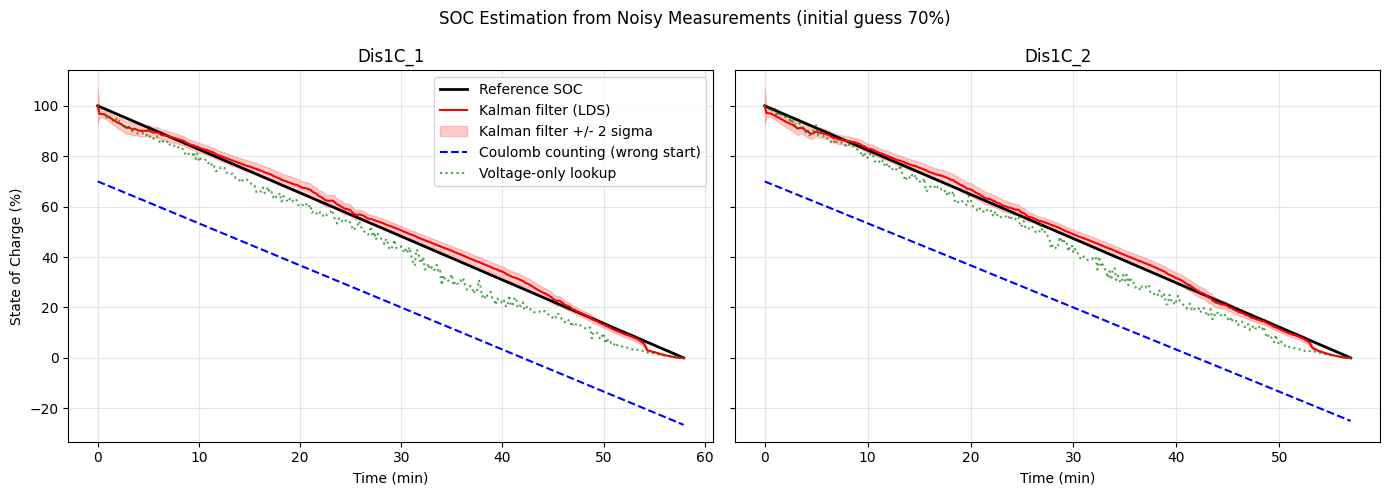

In [ ]:
# SOC estimates compared with the reference

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (name, d) in zip(axes, cycles.items()):
    r = runs[name]
    tm = d["t"] / 60
    ax.plot(tm, 100 * d["soc_ref"], "k", linewidth=2, label="Reference SOC")
    ax.plot(tm, 100 * r["kf"]["soc"], "r", label="Kalman filter (LDS)")
    ax.fill_between(tm,
                    100 * (r["kf"]["soc"] - 2 * r["kf"]["sd"]),
                    100 * (r["kf"]["soc"] + 2 * r["kf"]["sd"]),
                    color="r", alpha=0.2, label="Kalman filter +/- 2 sigma")
    ax.plot(tm, 100 * r["cc"], "b--", label="Coulomb counting (wrong start)")
    ax.plot(tm, 100 * r["ocv"], ":", color="green", alpha=0.7, label="Voltage-only lookup")
    ax.set_xlabel("Time (min)")
    ax.set_title(name)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("State of Charge (%)")
axes[0].legend()
plt.suptitle("SOC Estimation from Noisy Measurements (initial guess 70%)")
plt.tight_layout()
plt.show()

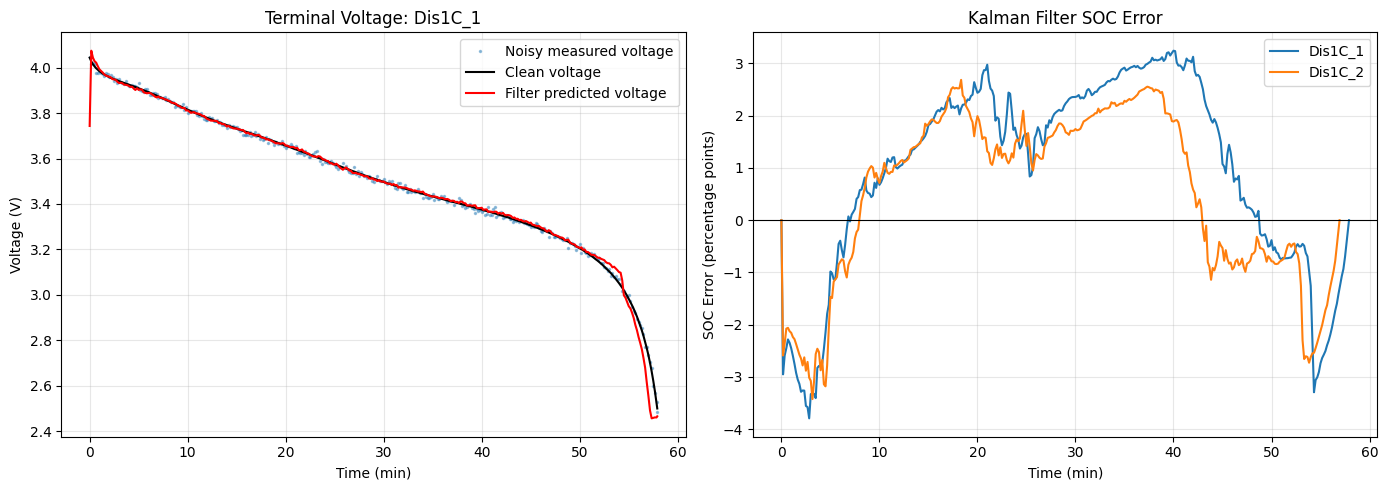

In [ ]:
# Voltage filtering and SOC error over time

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
d, r = cycles["Dis1C_1"], runs["Dis1C_1"]
tm = d["t"] / 60

axes[0].plot(tm, r["V_m"], ".", markersize=3, alpha=0.4, label="Noisy measured voltage")
axes[0].plot(tm, d["V"], "k", label="Clean voltage")
axes[0].plot(tm, r["kf"]["V"], "r", label="Filter predicted voltage")
axes[0].set_xlabel("Time (min)")
axes[0].set_ylabel("Voltage (V)")
axes[0].set_title("Terminal Voltage: Dis1C_1")
axes[0].legend()
axes[0].grid(alpha=0.3)

for name, dd in cycles.items():
    axes[1].plot(dd["t"] / 60, 100 * (runs[name]["kf"]["soc"] - dd["soc_ref"]), label=name)
axes[1].axhline(0, color="k", linewidth=0.8)
axes[1].set_xlabel("Time (min)")
axes[1].set_ylabel("SOC Error (percentage points)")
axes[1].set_title("Kalman Filter SOC Error")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

,Initial SOC Guess (%),Kalman Filter RMSE (%),Coulomb Counting RMSE (%)
0,50.0,2.096,47.868
1,60.0,2.241,37.873
2,70.0,2.266,27.881
3,80.0,2.308,17.897
4,90.0,2.327,7.956
5,100.0,2.850,2.485


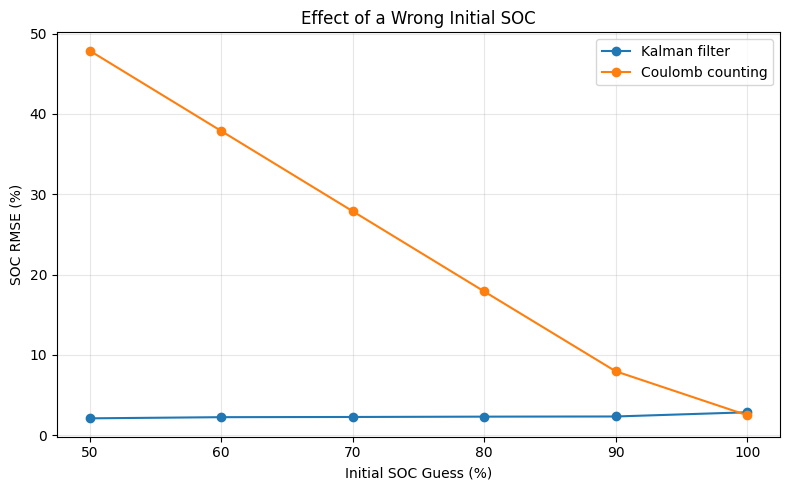

In [ ]:
# Sensitivity to the initial SOC guess (averaged over random noise realisations)

init_guesses = [0.50, 0.60, 0.70, 0.80, 0.90, 1.00]
n_trials = 10
rows = []

for soc0 in init_guesses:
    kf_err, cc_err = [], []
    for name, d in cycles.items():
        for trial in range(n_trials):
            rng = np.random.default_rng(1000 + trial)
            V_m, I_m, T_m = corrupt(d, SIG_V, SIG_I, SIG_T, rng)
            kf = kalman_filter(d, V_m, I_m, T_m, soc0, Q_NOMINAL, SIG_V, SIG_I)
            kf_err.append(rmse(kf["soc"], d["soc_ref"]))
            cc_err.append(rmse(coulomb_counting(d, I_m, soc0, Q_NOMINAL), d["soc_ref"]))
    rows.append({
        "Initial SOC Guess (%)": 100 * soc0,
        "Kalman Filter RMSE (%)": np.mean(kf_err),
        "Coulomb Counting RMSE (%)": np.mean(cc_err),
    })

init_df = pd.DataFrame(rows)
display(init_df.round(3))

plt.figure(figsize=(8, 5))
plt.plot(init_df["Initial SOC Guess (%)"], init_df["Kalman Filter RMSE (%)"], marker="o", label="Kalman filter")
plt.plot(init_df["Initial SOC Guess (%)"], init_df["Coulomb Counting RMSE (%)"], marker="o", label="Coulomb counting")
plt.xlabel("Initial SOC Guess (%)")
plt.ylabel("SOC RMSE (%)")
plt.title("Effect of a Wrong Initial SOC")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

,Noise Level,Voltage Noise (mV),Current Noise (A),Kalman Filter SOC RMSE (%),Coulomb Counting SOC RMSE (%),Capacity Error (%)
0,Low,5.0,0.02,2.371,27.879,3.569
1,Nominal,10.0,0.05,2.090,27.892,3.742
2,High,20.0,0.10,1.709,27.913,2.787
3,Very High,50.0,0.20,2.745,27.957,2.787


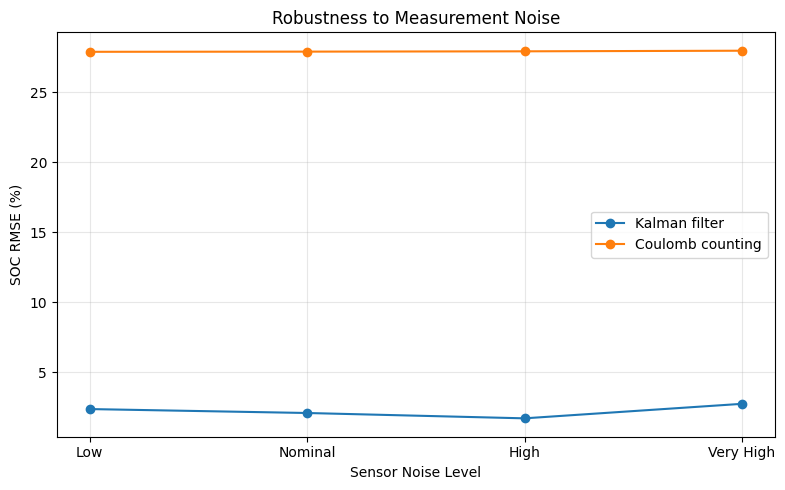

In [ ]:
# Sensitivity to sensor noise (averaged over random noise realisations)

noise_levels = [
    {"Level": "Low",       "sig_V": 0.005, "sig_I": 0.02},
    {"Level": "Nominal",   "sig_V": 0.010, "sig_I": 0.05},
    {"Level": "High",      "sig_V": 0.020, "sig_I": 0.10},
    {"Level": "Very High", "sig_V": 0.050, "sig_I": 0.20},
]
rows = []

for lvl in noise_levels:
    kf_err, cc_err, q_err = [], [], []
    for name, d in cycles.items():
        for trial in range(n_trials):
            rng = np.random.default_rng(2000 + trial)
            V_m, I_m, T_m = corrupt(d, lvl["sig_V"], lvl["sig_I"], SIG_T, rng)
            kf = kalman_filter(d, V_m, I_m, T_m, SOC0_GUESS, Q_NOMINAL, lvl["sig_V"], lvl["sig_I"])
            kf_err.append(rmse(kf["soc"], d["soc_ref"]))
            cc_err.append(rmse(coulomb_counting(d, I_m, SOC0_GUESS, Q_NOMINAL), d["soc_ref"]))
            q_err.append(100 * abs(kf["Q"][-1] - d["Q"]) / d["Q"])
    rows.append({
        "Noise Level": lvl["Level"],
        "Voltage Noise (mV)": 1000 * lvl["sig_V"],
        "Current Noise (A)": lvl["sig_I"],
        "Kalman Filter SOC RMSE (%)": np.mean(kf_err),
        "Coulomb Counting SOC RMSE (%)": np.mean(cc_err),
        "Capacity Error (%)": np.mean(q_err),
    })

noise_df = pd.DataFrame(rows)
display(noise_df.round(3))

plt.figure(figsize=(8, 5))
plt.plot(noise_df["Noise Level"], noise_df["Kalman Filter SOC RMSE (%)"], marker="o", label="Kalman filter")
plt.plot(noise_df["Noise Level"], noise_df["Coulomb Counting SOC RMSE (%)"], marker="o", label="Coulomb counting")
plt.xlabel("Sensor Noise Level")
plt.ylabel("SOC RMSE (%)")
plt.title("Robustness to Measurement Noise")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

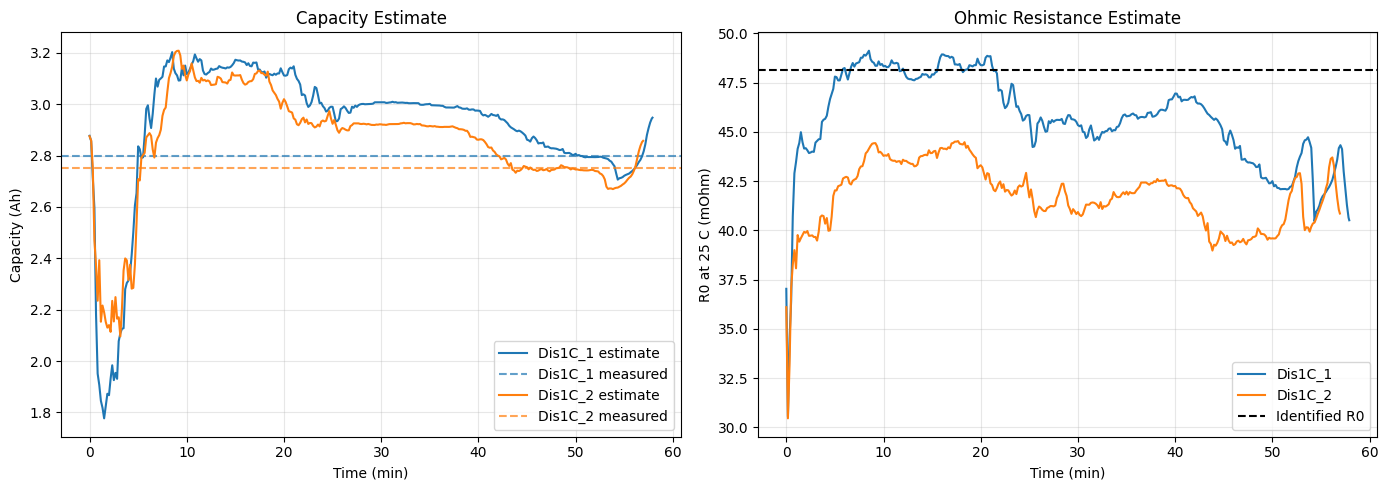

,Cycle,Measured Capacity (Ah),Estimated Capacity (Ah),Capacity Error (%),Measured SOH (%),Estimated SOH (%),Estimated R0 (mOhm)
0,Dis1C_1,2.798,2.948,5.351,96.491,101.654,40.514
1,Dis1C_2,2.752,2.858,3.856,94.884,98.543,40.856


In [ ]:
# Health estimation: capacity and resistance

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, d in cycles.items():
    tm = d["t"] / 60
    line, = axes[0].plot(tm, runs[name]["kf"]["Q"], label=f"{name} estimate")
    axes[0].axhline(d["Q"], linestyle="--", color=line.get_color(), alpha=0.7, label=f"{name} measured")
    axes[1].plot(tm, 1000 * runs[name]["kf"]["R0"], label=name)

axes[0].set_xlabel("Time (min)")
axes[0].set_ylabel("Capacity (Ah)")
axes[0].set_title("Capacity Estimate")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].axhline(1000 * R0_REF, color="k", linestyle="--", label="Identified R0")
axes[1].set_xlabel("Time (min)")
axes[1].set_ylabel("R0 at 25 C (mOhm)")
axes[1].set_title("Ohmic Resistance Estimate")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

health_rows = []
for name, d in cycles.items():
    q_est = runs[name]["kf"]["Q"][-1]
    health_rows.append({
        "Cycle": name,
        "Measured Capacity (Ah)": d["Q"],
        "Estimated Capacity (Ah)": q_est,
        "Capacity Error (%)": 100 * (q_est - d["Q"]) / d["Q"],
        "Measured SOH (%)": 100 * d["Q"] / Q_NOMINAL,
        "Estimated SOH (%)": 100 * q_est / Q_NOMINAL,
        "Estimated R0 (mOhm)": 1000 * runs[name]["kf"]["R0"][-1],
    })
health_df = pd.DataFrame(health_rows)
display(health_df.round(3))

Dis1C_1: mean residual = 2.93 mV, std = 33.39 mV
Dis1C_2: mean residual = 2.22 mV, std = 32.74 mV


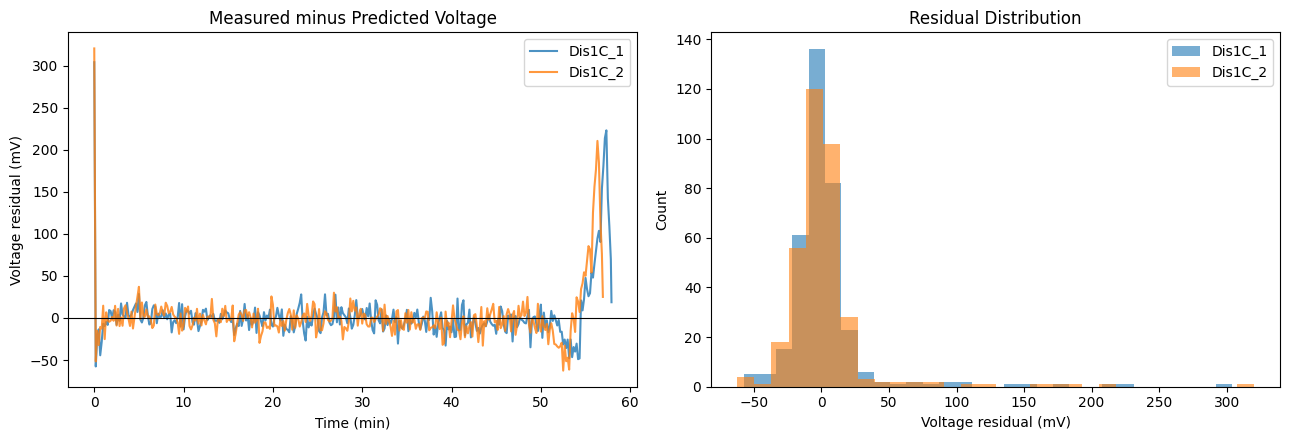

In [ ]:
# Residual (innovation) check: is the voltage error close to zero-mean noise?

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, d in cycles.items():
    resid = runs[name]["V_m"] - runs[name]["kf"]["V"]
    axes[0].plot(d["t"] / 60, 1000 * resid, label=name, alpha=0.8)
    axes[1].hist(1000 * resid, bins=30, alpha=0.6, label=name)
    print(f"{name}: mean residual = {1000 * resid.mean():.2f} mV, std = {1000 * resid.std():.2f} mV")

axes[0].axhline(0, color="k", linewidth=0.8)
axes[0].set_xlabel("Time (min)")
axes[0].set_ylabel("Voltage residual (mV)")
axes[0].set_title("Measured minus Predicted Voltage")
axes[0].legend()
axes[1].set_xlabel("Voltage residual (mV)")
axes[1].set_ylabel("Count")
axes[1].set_title("Residual Distribution")
axes[1].legend()
plt.tight_layout()
plt.show()

## Results and Discussion

A Kalman filter (a linear dynamical system with a locally linearised voltage measurement) was applied to two full 1C discharges of a Panasonic 18650PF cell at 25 °C. The filter started from a deliberately wrong SOC (70% instead of 100%) and a wrong capacity (2.9 Ah), and received noisy current, voltage and temperature measurements (10 mV, 0.05 A, 0.5 °C added noise).

**SOC accuracy (nominal noise):** the Kalman filter reached an SOC RMSE of about 2.1% (Dis1C_1) and 1.7% (Dis1C_2). Coulomb counting from the same wrong start had an RMSE of about 28%, because it cannot correct an initial error. A voltage-only lookup of the OCV curve gave about 5.4% and 4.7%.

**Initial SOC sensitivity:** for initial guesses between 50% and 90%, the Kalman filter RMSE stayed between about 2.1% and 2.3%, while coulomb counting ranged from about 48% down to 8%. When the initial guess was correct (100%), coulomb counting (about 2.5%) was slightly better than the Kalman filter (about 2.9%).

**Noise sensitivity:** the Kalman filter RMSE stayed between about 1.7% and 2.7% across the four noise levels, while coulomb counting stayed near 28% because its error is dominated by the wrong start.

**Health estimation:** the estimated capacities were 2.95 Ah and 2.86 Ah against measured values of 2.80 Ah and 2.75 Ah (errors of about +5.4% and +3.9%). The estimated SOH of 101.7% for Dis1C_1 is above 100%, so the capacity estimate is only approximate. The estimated ohmic resistance (about 40.5 mOhm) is lower than the identified value (48.1 mOhm), so it should be treated as an indicative signal only.

**Residual check:** the voltage residuals have a mean near 0 mV but a standard deviation of about 33 mV, far above the 10 mV noise assumed by the filter. This indicates model mismatch, so the reported uncertainty band is too narrow.

## Conclusion

The experiment shows that fusing a battery model with noisy voltage measurements recovers the hidden SOC far better than integrating current alone when the starting point is unknown, and better than a voltage-only lookup. Capacity and resistance can be tracked as slowly varying states, but the estimates from a single discharge are rough.

## Limitations

- Only the 25 °C data was available. The fitted temperature coefficients (Ea0 and Ea1) came out as zero, so the temperature dependence of the resistances was not identified and the model is effectively temperature-independent. Battery temperature rose only from about 25 °C to 33 °C through self-heating.
- The reference SOC comes from coulomb counting, assuming each discharge runs from 100% to 0%. It is not an independent measurement of true SOC.
- The sensor noise was added synthetically to otherwise clean measurements.
- The RC time constant reached its upper bound (500 s), and the voltage model error is about 37 mV, so the one-RC model is a simplification.
- Only two cycles were used, so the health results cannot show ageing trends. Capacity estimates vary with the noise realisation.
- The voltage measurement is nonlinear in SOC, so the filter is strictly an extended Kalman filter around a linear state model.